In [5]:
%pip install seaborn sdmetrics

  Obtaining dependency information for sdmetrics from https://files.pythonhosted.org/packages/3b/6f/2fba5906776954feea80749ea759a015c605086fec1dfe440bd03dc33873/sdmetrics-0.20.1-py3-none-any.whl.metadata
  Using cached sdmetrics-0.20.1-py3-none-any.whl.metadata (9.4 kB)
  Obtaining dependency information for copulas>=0.12.1 from https://files.pythonhosted.org/packages/4c/31/3ddc47aa7d4c6c4f0adc6fe5a393a408a729f3053f1c6daf8367ad858a2b/copulas-0.12.2-py3-none-any.whl.metadata
  Using cached copulas-0.12.2-py3-none-any.whl.metadata (9.4 kB)
  Obtaining dependency information for plotly>=5.19.0 from https://files.pythonhosted.org/packages/75/f3/f8cb7066f761e2530e1280889e3413769891e349fca35ee7290e4ace35f5/plotly-6.1.1-py3-none-any.whl.metadata
  Using cached plotly-6.1.1-py3-none-any.whl.metadata (6.9 kB)
Using cached sdmetrics-0.20.1-py3-none-any.whl (193 kB)
Using cached copulas-0.12.2-py3-none-any.whl (52 kB)
Using cached plotly-6.1.1-py3-none-any.whl (16.1 MB)
Note: you may need to rest


[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import torch
import pandas as pd
import json
import seaborn as sns
from utils.plot import calculate_cramers_v_matrix, compare_distributions, plot_latent_space, distribution_metrics

In [ ]:
with open("./params.json", "r") as params_json:
    params = json.load(params_json)
    categorical_columns = [
        key
        for key, value in params["columns"].items()
        if value.get("sdtype") == "categorical"
    ]
    continuous_columns = [
        key
        for key, value in params["columns"].items()
        if value.get("sdtype") == "numerical"
    ]

In [25]:
'''# transform unix timestamps to actual datetimes

for column in continuous_columns:
    try:
        unix_to_datetime(syn_df, column)
        unix_to_datetime(data_supp, column)
    except Exception as e:
        print(e)'''

'# transform unix timestamps to actual datetimes\n\nfor column in continuous_columns:\n    try:\n        unix_to_datetime(syn_df, column)\n        unix_to_datetime(data_supp, column)\n    except Exception as e:\n        print(e)'

In [8]:
data_supp = pd.read_csv("./data/bank-full.csv", sep=';')
syn_df = pd.read_csv("./data/synthetic.csv")

In [9]:
data_supp.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [10]:
syn_df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,41,blue-collar,married,secondary,no,593,yes,no,cellular,14,may,36,6,356,1,failure,no
1,28,technician,married,secondary,no,1852,yes,no,cellular,5,feb,420,2,-1,0,unknown,no
2,58,blue-collar,married,primary,no,1204,yes,yes,cellular,20,jul,92,8,-1,0,unknown,no
3,35,blue-collar,divorced,secondary,no,1148,yes,yes,cellular,0,may,135,3,181,1,failure,no
4,42,unemployed,married,unknown,no,2309,no,no,cellular,2,aug,195,2,-1,0,failure,no


In [12]:
'''label = "organisaatio"

dl = DataLoader(TensorDataset(torch.tensor(x_train)), batch_size=1024, shuffle=False)

plot_latent_space(
    vae,
    dl,
    label_series = data_supp[label],
    method = "TSNE",
    title = f"VAE latent space for '{label}'"
)'''

'label = "organisaatio"\n\ndl = DataLoader(TensorDataset(torch.tensor(x_train)), batch_size=1024, shuffle=False)\n\nplot_latent_space(\n    vae,\n    dl,\n    label_series = data_supp[label],\n    method = "TSNE",\n    title = f"VAE latent space for \'{label}\'"\n)'

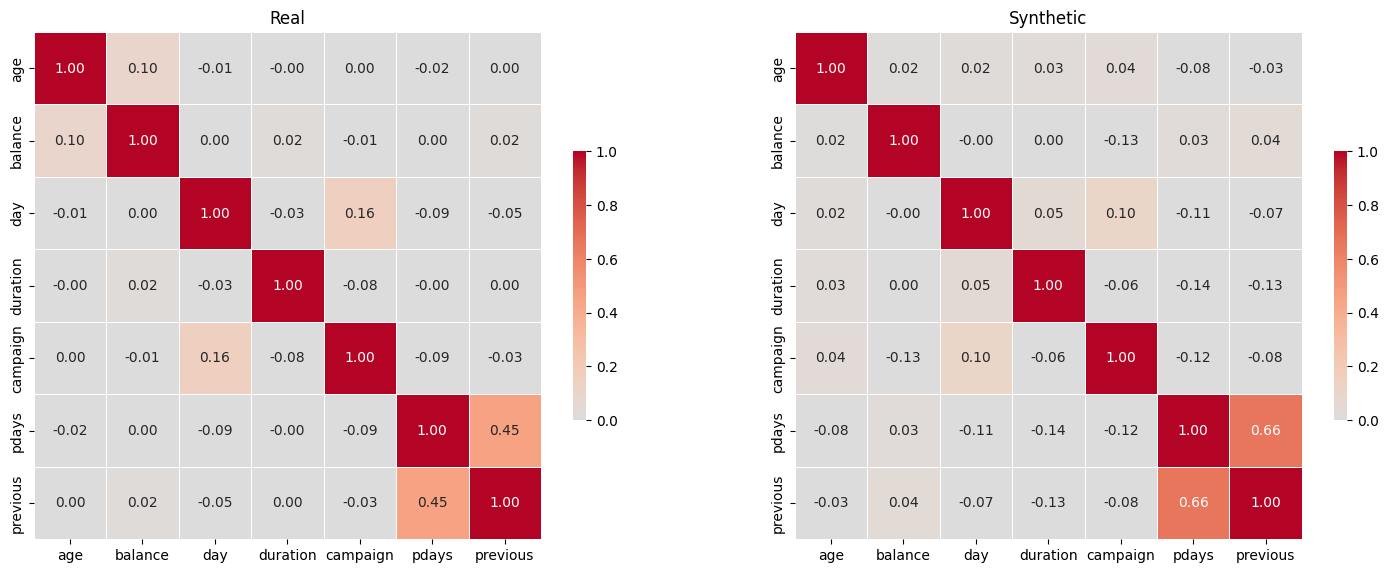

In [24]:
# correlation of timestamps (has to be calculated on unix timestamps)
corr_org = data_supp[continuous_columns].corr()
corr_synth = syn_df[continuous_columns].corr()
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(corr_org, center=0, cmap="coolwarm", vmin=0, annot=True, fmt=".2f", vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, ax=ax[0]); ax[0].set_title("Real")
sns.heatmap(corr_synth, center=0, cmap="coolwarm", vmin=0, annot=True, fmt=".2f", vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .5}, ax=ax[1]); ax[1].set_title("Synthetic")
plt.show()

In [14]:
real_cv  = calculate_cramers_v_matrix(data_supp, categorical_columns)
synth_cv = calculate_cramers_v_matrix(syn_df, categorical_columns)

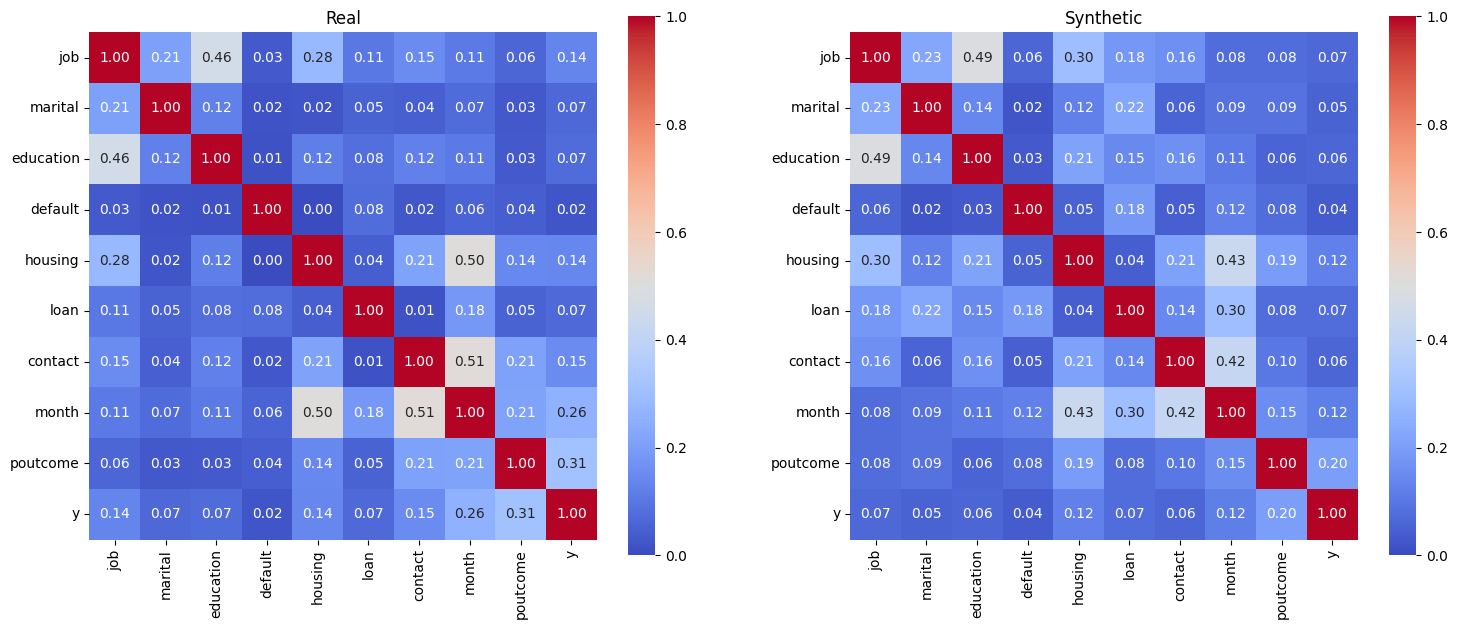

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(real_cv,  cmap="coolwarm", vmin=0, annot=True, fmt=".2f", vmax=1, square=True, ax=ax[0]); ax[0].set_title("Real")
sns.heatmap(synth_cv, cmap="coolwarm", vmin=0, annot=True, fmt=".2f", vmax=1, square=True, ax=ax[1]); ax[1].set_title("Synthetic")
plt.show()

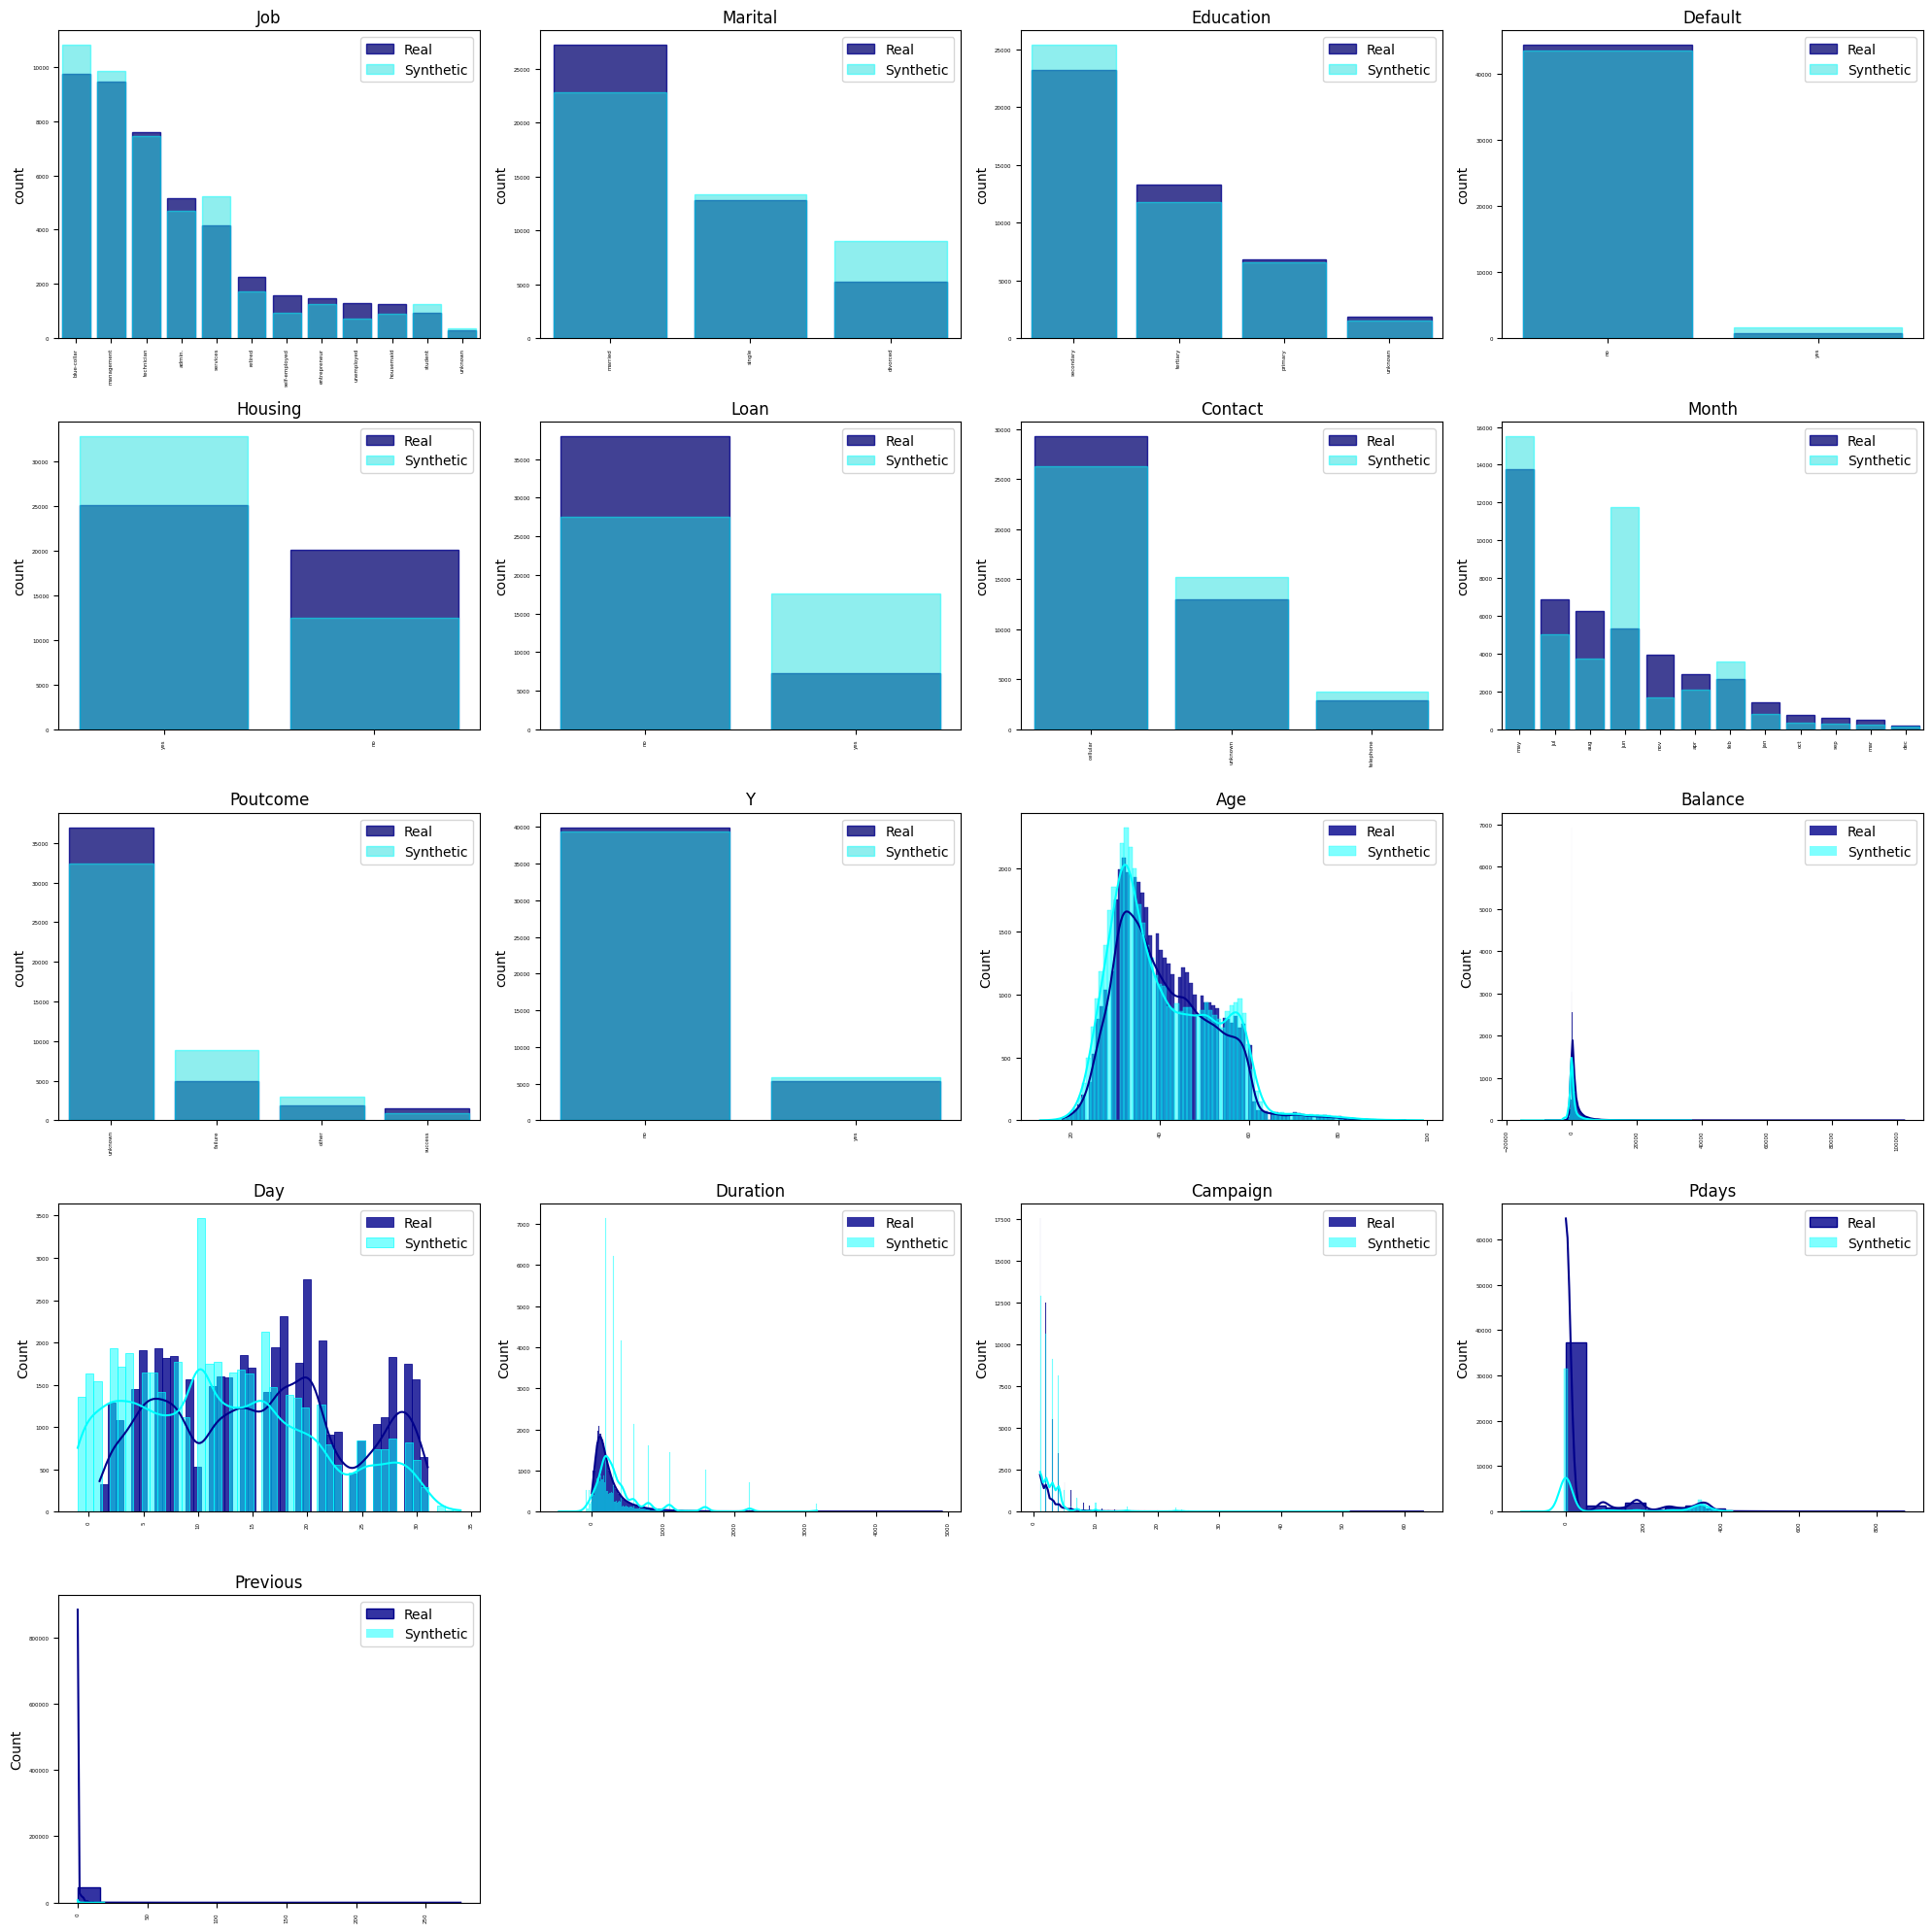

In [16]:
compare_distributions(data_supp, syn_df, categorical_columns, continuous_columns)

In [19]:
report = distribution_metrics(data_supp, syn_df, './params.json')

Generating report ...

(1/2) Evaluating Column Shapes: |██████████| 17/17 [00:00<00:00, 63.53it/s]|
Column Shapes Score: 86.65%

(2/2) Evaluating Column Pair Trends: |██████████| 136/136 [00:01<00:00, 71.40it/s]|
Column Pair Trends Score: 68.73%

Overall Score (Average): 77.69%



In [20]:
report.get_details(property_name='Column Shapes')

,Column,Metric,Score
0,age,KSComplement,0.939992
1,job,TVComplement,0.935038
2,marital,TVComplement,0.902303
3,education,TVComplement,0.952357
4,default,TVComplement,0.982195
5,balance,KSComplement,0.673509
6,housing,TVComplement,0.830749
7,loan,TVComplement,0.770299
8,contact,TVComplement,0.932605
9,day,KSComplement,0.815111


In [21]:
report.get_details(property_name='Column Pair Trends')

,Column 1,Column 2,Metric,Score,Real Correlation,Synthetic Correlation
0,age,job,ContingencySimilarity,0.856561,NaN,NaN
1,age,marital,ContingencySimilarity,0.851872,NaN,NaN
2,age,education,ContingencySimilarity,0.881622,NaN,NaN
3,age,default,ContingencySimilarity,0.897768,NaN,NaN
4,age,balance,CorrelationSimilarity,0.958640,0.097783,0.015064
...,...,...,...,...,...,...
131,pdays,poutcome,ContingencySimilarity,0.058437,NaN,NaN
132,pdays,y,ContingencySimilarity,0.092654,NaN,NaN
133,previous,poutcome,ContingencySimilarity,0.870032,NaN,NaN
134,previous,y,ContingencySimilarity,0.897282,NaN,NaN


In [22]:
report.get_properties()

,Property,Score
0,Column Shapes,0.866526
1,Column Pair Trends,0.687306


In [23]:
syn_df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,41,blue-collar,married,secondary,no,593,yes,no,cellular,14,may,36,6,356,1,failure,no
1,28,technician,married,secondary,no,1852,yes,no,cellular,5,feb,420,2,-1,0,unknown,no
2,58,blue-collar,married,primary,no,1204,yes,yes,cellular,20,jul,92,8,-1,0,unknown,no
3,35,blue-collar,divorced,secondary,no,1148,yes,yes,cellular,0,may,135,3,181,1,failure,no
4,42,unemployed,married,unknown,no,2309,no,no,cellular,2,aug,195,2,-1,0,failure,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,25,technician,single,secondary,no,120,no,no,cellular,1,feb,420,1,-1,0,unknown,no
45207,31,management,single,tertiary,no,732,yes,no,cellular,13,may,297,3,343,1,failure,no
45208,30,technician,single,secondary,no,66,no,yes,unknown,27,may,443,1,-1,0,unknown,no
45209,31,blue-collar,single,unknown,no,924,no,no,unknown,0,jun,420,2,351,2,failure,yes
